### Global Imports

In [48]:
import pandas as pd
from IPython.display import display
import missingno as msno
import matplotlib.pyplot as plt

### Selected Datasets


In [2]:
df_met = pd.read_csv("datasets/Meteorologi_2024-2026.csv")
df_air = pd.read_csv("datasets/ISPU_2024-2025.csv")

## 1. Data Inspection

In [3]:
# Sanity Checking
print("Meteorologi Data Shape: ", df_met.shape)
print("Air Quality Data Shape: ", df_air.shape)

Meteorologi Data Shape:  (223809, 8)
Air Quality Data Shape:  (3501, 13)


In [4]:
# Understanding current datatypes
print("Data Meteorologi")
display(df_met.info())
print("=====")
print("Data Air Quality")
display(df_air.info())

Data Meteorologi
<class 'pandas.DataFrame'>
RangeIndex: 223809 entries, 0 to 223808
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   periode_data        223809 non-null  int64  
 1   tanggal             223809 non-null  int64  
 2   stasiun_pengamatan  223809 non-null  str    
 3   grad                222973 non-null  float64
 4   temp_air            222932 non-null  float64
 5   hum_air             217106 non-null  float64
 6   ff                  222764 non-null  float64
 7   rain                222656 non-null  float64
dtypes: float64(5), int64(2), str(1)
memory usage: 13.7 MB


None

=====
Data Air Quality
<class 'pandas.DataFrame'>
RangeIndex: 3501 entries, 0 to 3500
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   parameter_pencemar_kritis  3436 non-null   str    
 1   kategori                   3500 non-null   str    
 2   periode_data               3501 non-null   int64  
 3   bulan                      3501 non-null   int64  
 4   tanggal                    3501 non-null   int64  
 5   stasiun                    3501 non-null   str    
 6   pm_sepuluh                 3237 non-null   float64
 7   pm_duakomalima             3440 non-null   float64
 8   sulfur_dioksida            3445 non-null   float64
 9   karbon_monoksida           3451 non-null   float64
 10  ozon                       3455 non-null   float64
 11  nitrogen_dioksida          3432 non-null   float64
 12  max                        3493 non-null   float64
dtypes: float64(7), int64(3), str(3)
memo

None

### **1.1.1 What are the date ranges of each dataset?**

In [5]:
MET_TEMPORAL = ["periode_data", "tanggal"]
AIR_TEMPORAL = ["periode_data", "bulan", "tanggal"]

In [6]:
# Examples
print("=== Data Meteorologi Temporal ===")
display(df_met[MET_TEMPORAL].sample(5))

print("=== Data Air Quality Temporal ===")
display(df_air[AIR_TEMPORAL].sample(5))

=== Data Meteorologi Temporal ===


,periode_data,tanggal
58151,202404,27
152932,202510,15
173920,202512,30
11407,202408,25
115621,202504,24


=== Data Air Quality Temporal ===


,periode_data,bulan,tanggal
1806,202412,12,8
10,202401,1,11
1274,202409,9,25
527,202404,4,13
1871,202501,1,11


In [7]:
# Finding Temporal Range
print("=== Temporal Feature Range of Data Meteorologi ===")
print(f"{min(df_met["periode_data"])} -> {max(df_met["periode_data"])}\n")

print("=== Temporal Feature Range of Data Air Quality ===")
print(f"{min(df_air["periode_data"])} -> {max(df_air["periode_data"])}")

=== Temporal Feature Range of Data Meteorologi ===
202401 -> 202607

=== Temporal Feature Range of Data Air Quality ===
202401 -> 202511


### **1.1.2 Where was the dataset recorded?**

In [35]:
print("=== Data Meteorologi Stations ===")
met_stations = df_met["stasiun_pengamatan"].value_counts()
met_stations

=== Data Meteorologi Stations ===


stasiun_pengamatan
DKI3 Jagakarsa                        33303
DKI4 Lubang Buaya                     33125
DKI2 Kelapa Gading                    21707
DKI1 Bundaran Hotel Indonesia (HI)    17562
DKI5 Kebon Jeruk                      17555
DKI1 Bundaran HI                      15957
DKI5 Kebun Jeruk                      15884
\tDKI2 Kelapa Gading                  11678
DKI4 LUBANG BUAYA                      8740
DKI1 BUNDARAN HI                       8659
DKI3 JAGAKARSA                         8522
DKI2 KELAPA GADING                     7234
DKI5 KEBON JERUK                       5801
DKI5 KEBUN JERUK                       2915
DKI5                                   2831
DKI4                                   2803
DKI3                                   2796
DKI2                                   2695
DKI1                                   2602
\tDKI2 KELAPA GADING                   1440
Name: count, dtype: int64

In [37]:
print("=== Data Air Quality Stations ===")
air_stations = df_air["stasiun"].value_counts()
air_stations

=== Data Air Quality Stations ===


stasiun
DKI2 Kelapa Gading                     640
DKI3 Jagakarsa                         640
DKI4 Lubang Buaya                      640
DKI5 Kebon Jeruk                       551
DKI1 Bundaran Hotel Indonesia (HI)     487
DKI1  Bundaran Hotel Indonesia (HI)     92
DKI1  Bunderan HI                       90
DKI5 Kebon Jeruk Jakarta Barat          90
DKI2  Kelapa Gading                     60
DKI4  Lubang Buaya                      60
DKI5  Kebon Jeruk  Jakarta Barat        60
DKI3  Jagakarsa                         60
DKI1 Bundaran Hotel Indonesia  HI       31
Name: count, dtype: int64

### **1.1.3 How did each dataset track their data?**

In [25]:
# 1. Data Meteorologi
met_counts = df_met.groupby(by=["stasiun_pengamatan", "periode_data", "tanggal"]).count()
met_counts


grad  temp_air  hum_air  ff  rain
stasiun_pengamatan   periode_data tanggal                                   
\tDKI2 KELAPA GADING 202512       1          48        48       48  48    48
                                  2          48        48       48  48    48
                                  3          48        48       48  48    48
                                  4          48        48       48  48    48
                                  5          48        48       48  48    48
...                                         ...       ...      ...  ..   ...
DKI5 Kebun Jeruk     202511       26         48        48       48  48    48
                                  27         48        48       48  48    48
                                  28         48        48       48  48    48
                                  29         48        48       48  48    48
                                  30         48        48       48  48    48

[4711 rows x 5 columns]

In [29]:
# 2. Data Air Quality
air_counts = df_air.groupby(["stasiun", "periode_data", "bulan", "tanggal"]).count()
air_counts

parameter_pencemar_kritis  \
stasiun                             periode_data bulan tanggal                              
DKI1  Bundaran Hotel Indonesia (HI) 202401       1     1                                1   
                                                       2                                1   
                                                       3                                1   
                                                       4                                1   
                                                       5                                1   
...                                                                                   ...   
DKI5 Kebon Jeruk Jakarta Barat      202502       2     24                               1   
                                                       25                               1   
                                                       26                               1   
                                                       27                               1   
                                                       28                               1   

                                                                kategori  \
stasiun                             periode_data bulan tanggal             
DKI1  Bundaran Hotel Indonesia (HI) 202401       1     1               1   
                                                       2               1   
                                                       3               1   
                                                       4               1   
                                                       5               1   
...                                                                  ...   
DKI5 Kebon Jeruk Jakarta Barat      202502       2     24              1   
                                                       25              1   
                                                       26              1   
                                                       27              1   
                                                       28              1   

                                                                pm_sepuluh  \
stasiun                             periode_data bulan tanggal               
DKI1  Bundaran Hotel Indonesia (HI) 202401       1     1                 1   
                                                       2                 1   
                                                       3                 1   
                                                       4                 1   
                                                       5                 1   
...                                                                    ...   
DKI5 Kebon Jeruk Jakarta Barat      202502       2     24                1   
                                                       25                1   
                                                       26                1   
                                                       27                1   
                                                       28                1   

                                                                pm_duakomalima  \
stasiun                             periode_data bulan tanggal                   
DKI1  Bundaran Hotel Indonesia (HI) 202401       1     1                     1   
                                                       2                     1   
                                                       3                     1   
                                                       4                     0   
                                                       5                     1   
...                                                                        ...   
DKI5 Kebon Jeruk Jakarta Barat      202502       2     24                    1   
                                                       25                    1   
                              

### **1.1.4 Are there any missing or null values?**

In [46]:
print("=== Data Meteorologi Quality Inspections ===")
missing_met = pd.DataFrame({
    "Missing Count": df_met.isna().sum(),
    "Missing Count (pct)": df_met.isna().sum() / len(df_met)
})
print("Missing Values")
display(missing_met)
print(f"\nDuplicated Rows Count: {df_met.duplicated().sum()}\n")

print("=== Data Air Qualiy Quality Inspections ===")
missing_air = pd.DataFrame({
    "Missing Count": df_air.isna().sum(),
    "Missing Count (pct)": df_air.isna().sum() / len(df_met)
})
print("Missing Values")
display(missing_air)
print(f"\nDuplicated Rows Count: {df_air.duplicated().sum()}")





=== Data Meteorologi Quality Inspections ===
Missing Values


,Missing Count,Missing Count (pct)
periode_data,0,0.000000
tanggal,0,0.000000
stasiun_pengamatan,0,0.000000
grad,836,0.003735
temp_air,877,0.003919
hum_air,6703,0.029950
ff,1045,0.004669
rain,1153,0.005152



Duplicated Rows Count: 0

=== Data Air Qualiy Quality Inspections ===
Missing Values


,Missing Count,Missing Count (pct)
parameter_pencemar_kritis,65,0.000290
kategori,1,0.000004
periode_data,0,0.000000
bulan,0,0.000000
tanggal,0,0.000000
stasiun,0,0.000000
pm_sepuluh,264,0.001180
pm_duakomalima,61,0.000273
sulfur_dioksida,56,0.000250
karbon_monoksida,50,0.000223



Duplicated Rows Count: 0


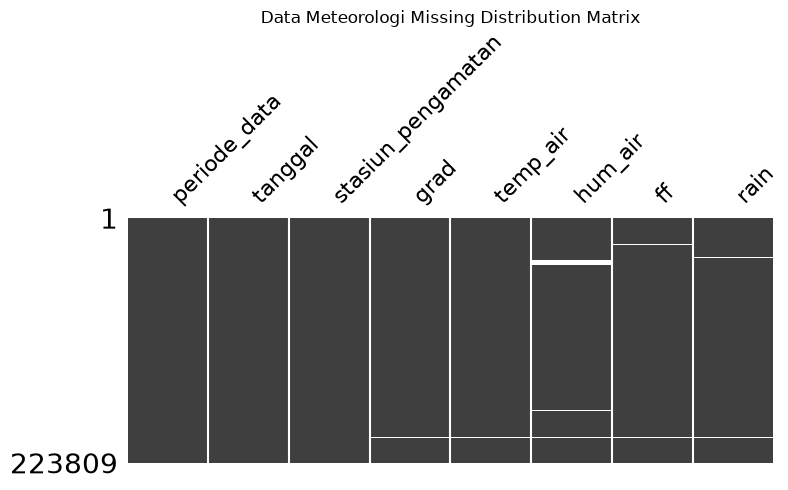

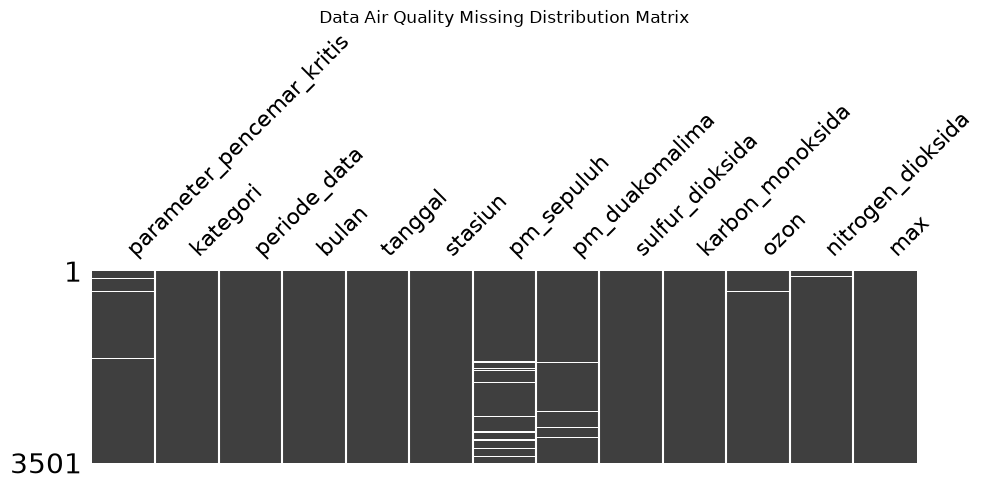

In [52]:
# Distribution Matrix
fig, ax = plt.subplots(figsize=(8, 5))
msno.matrix(df_met, ax=ax, sparkline=False)
ax.set_title("Data Meteorologi Missing Distribution Matrix")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
msno.matrix(df_air, ax=ax, sparkline=False)
ax.set_title("Data Air Quality Missing Distribution Matrix")
plt.tight_layout()
plt.show()

### **1.1.5 How are the values distributed in each dataset?**